# Exploratory analysis of the synthetic assignment data

Regenerate the CSV with `python ml/data/generate.py`.

## 1. Load data

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

df = pd.read_csv("../data/synthetic_assignments.csv", parse_dates=["assigned_date", "due_date"])

# Logical orderings, smallest workload first
TYPE_ORDER = ["Reading", "Homework", "Lab", "Exam", "Project"]
DIFFICULTY_ORDER = ["Easy", "Medium", "Hard"]

# Chart styling: one hue, recessive axes and grid
BLUE = "#2a78d6"
INK = "#52514e"
GRID = "#e1e0d9"
plt.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRID,
    "xtick.color": INK,
    "ytick.color": INK,
})


def mean_hours_bar(group_col, order, title):
    """Plot mean actual_hrs per group as a labeled bar chart."""
    means = df.groupby(group_col)["actual_hrs"].mean().reindex(order)
    fig, ax = plt.subplots(figsize=(7, 3.5))
    bars = ax.bar(means.index, means.values, width=0.55, color=BLUE)
    ax.bar_label(bars, fmt="%.2f", padding=3, color=INK)
    ax.set_title(title, loc="left")
    ax.set_ylabel("Mean hours")
    ax.grid(axis="x", visible=False)
    ax.margins(y=0.15)
    plt.show()
    return means.round(2)


df.head()

,student_id,course,title,type,difficulty,assigned_date,due_date,days_until_due,actual_hrs
0,1,CPE 595,Reading 1,Reading,Medium,2026-09-07,2026-09-11,4,1.75
1,1,CPE 595,Reading 2,Reading,Easy,2026-09-07,2026-09-12,5,0.75
2,1,MA 222,Lab 1,Lab,Hard,2026-09-11,2026-09-17,6,7.50
3,1,MA 222,Reading 1,Reading,Medium,2026-09-14,2026-09-17,3,2.00
4,1,MA 222,Reading 2,Reading,Medium,2026-09-14,2026-09-18,4,2.25


## 2. Row counts

In [2]:
print(f"Rows: {len(df)}")
print(f"Students: {df['student_id'].nunique()}")

# Assignments per student
print(df.groupby("student_id").size().describe().round(1).to_string())

df["type"].value_counts().reindex(TYPE_ORDER)

Rows: 1373
Students: 50
count    50.0
mean     27.5
std       6.8
min      15.0
25%      22.2
50%      29.0
75%      32.0
max      40.0


type
Reading     350
Homework    543
Lab         187
Exam        168
Project     125
Name: count, dtype: int64

## 3. Hours distribution

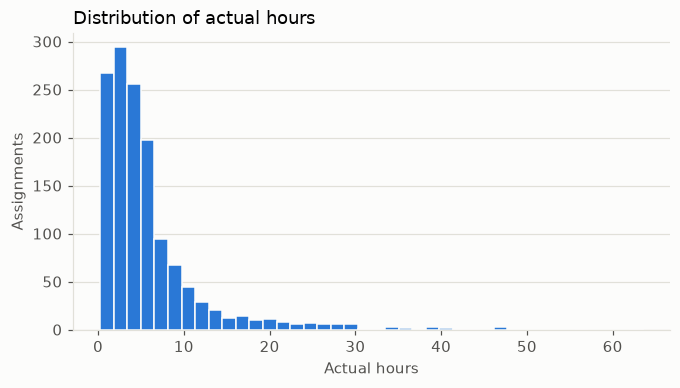

count    1373.00
mean        6.00
std         6.62
min         0.25
25%         2.25
50%         4.00
75%         6.75
max        63.50
Name: actual_hrs, dtype: float64

In [3]:
# Long right tail comes from Projects
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(df["actual_hrs"], bins=40, color=BLUE, edgecolor="#fcfcfb", linewidth=1)
ax.set_title("Distribution of actual hours", loc="left")
ax.set_xlabel("Actual hours")
ax.set_ylabel("Assignments")
ax.grid(axis="x", visible=False)
plt.show()

df["actual_hrs"].describe().round(2)

## 4. Mean hours by type

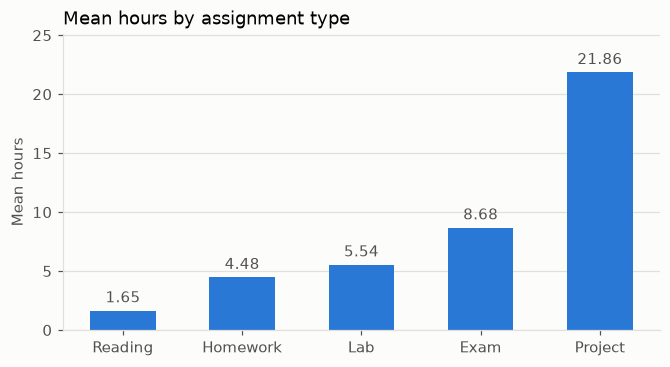

type
Reading      1.65
Homework     4.48
Lab          5.54
Exam         8.68
Project     21.86
Name: actual_hrs, dtype: float64

In [4]:
mean_hours_bar("type", TYPE_ORDER, "Mean hours by assignment type")

## 5. Mean hours by difficulty

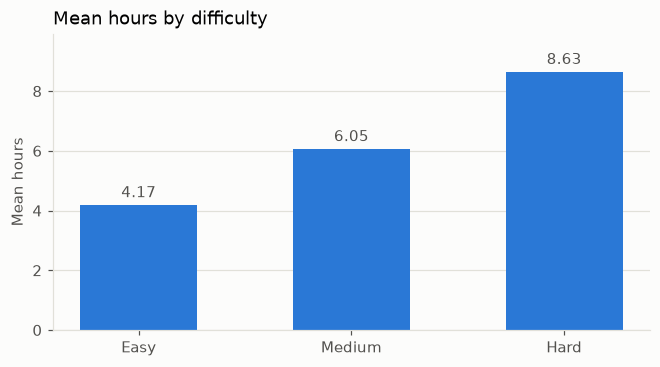

difficulty
Easy      4.17
Medium    6.05
Hard      8.63
Name: actual_hrs, dtype: float64

In [5]:
mean_hours_bar("difficulty", DIFFICULTY_ORDER, "Mean hours by difficulty")

## 6. Mean hours by course

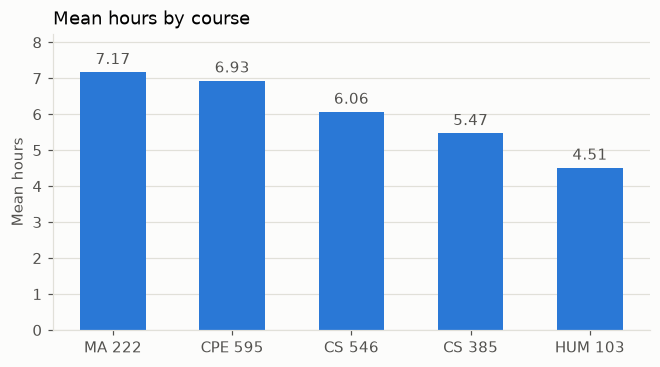

course
MA 222     7.17
CPE 595    6.93
CS 546     6.06
CS 385     5.47
HUM 103    4.51
Name: actual_hrs, dtype: float64

In [6]:
# Sorted high to low
course_order = df.groupby("course")["actual_hrs"].mean().sort_values(ascending=False).index.tolist()
mean_hours_bar("course", course_order, "Mean hours by course")

## 7. Type x difficulty heatmap

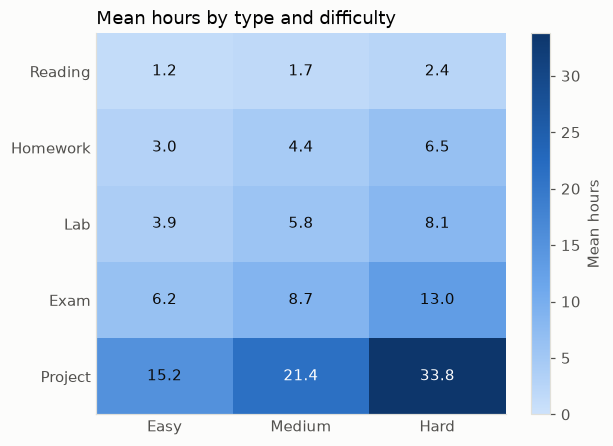

difficulty,Easy,Medium,Hard
type,,,
Reading,1.16,1.66,2.38
Homework,3.01,4.44,6.45
Lab,3.94,5.79,8.07
Exam,6.23,8.66,13.02
Project,15.17,21.36,33.77


In [7]:
pivot = df.pivot_table(index="type", columns="difficulty", values="actual_hrs", aggfunc="mean")
pivot = pivot.reindex(index=TYPE_ORDER, columns=DIFFICULTY_ORDER)

# Single-hue sequential ramp, light to dark
cmap = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#6da7ec", "#256abf", "#0d366b"])

fig, ax = plt.subplots(figsize=(6, 4.5))
image = ax.imshow(pivot.values, cmap=cmap, aspect="auto", vmin=0)
ax.set_xticks(range(len(pivot.columns)), pivot.columns)
ax.set_yticks(range(len(pivot.index)), pivot.index)
ax.grid(False)
ax.tick_params(length=0)
ax.set_title("Mean hours by type and difficulty", loc="left")
fig.colorbar(image, ax=ax, label="Mean hours")

# Annotate cells, switching text color on the darker half of the scale
threshold = pivot.values.max() * 0.45
for row, type_name in enumerate(pivot.index):
    for col, difficulty in enumerate(pivot.columns):
        value = pivot.loc[type_name, difficulty]
        ax.text(col, row, f"{value:.1f}", ha="center", va="center",
                color="white" if value > threshold else "#0b0b0b")
plt.show()

pivot.round(2)